# What Drives Bike-Share Demand? Initial Report and Exploratory Data Analysis

**Required Capstone Assignment 20.1: Initial Report and Exploratory Data Analysis (EDA)**

**Author:** Amit Kumar Ray

**Data:** UCI *Bike Sharing Dataset* (Capital Bikeshare, Washington D.C., 2011-2012; Fanaee-T & Gama, 2013)

## Contents

1. Research question and why it matters
2. Data understanding, quality checks and cleaning
3. Exploratory data analysis (including outlier analysis)
4. Data preparation and feature engineering
5. Baseline modelling and evaluation metric
6. Model evaluation and error analysis
7. Executive brief: findings, recommendations, next steps

## 1. Research question and why it matters

**Research question:** *How much of the hourly demand for shared bikes can be explained and predicted from the time of day, the calendar and the weather, and which of those factors matter most?*

**Why it matters:** a bike-share operator has to put the right number of bikes at the right stations at the right time. Too few bikes means lost rentals and unhappy riders. Too many means idle bikes and rebalancing trucks driving around for nothing. A model that forecasts demand a day or more ahead from the calendar and the weather forecast can drive staffing, rebalancing and maintenance schedules. Knowing which factors drive demand also tells planners when it is cheap to do maintenance (low-demand hours) and which weather conditions need a contingency plan.

**Type of problem:** supervised regression on the hourly rental count `cnt`.

**Success criteria:** the model must beat two simple baselines (the overall mean and a "typical day" lookup table) on data from a period that was *not* used for training. Error is reported as RMSE and MAE in bikes per hour, together with R².

In [1]:
import warnings
warnings.filterwarnings('ignore')   # keep the notebook output free of library deprecation chatter

from pathlib import Path

# data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# modelling (scikit-learn)
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option('display.max_columns', 30)

# one consistent, uncluttered plot style for every figure
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.titleweight': 'bold',
})

RANDOM_STATE = 42               # fixed seed so the results are reproducible
IMG = Path('images')            # figures are also saved here for the README
IMG.mkdir(exist_ok=True)


def save(fig, name):
    # Save a figure to the images folder (used by the README)
    fig.savefig(IMG / name, dpi=130, bbox_inches='tight')

## 2. Data understanding, quality checks and cleaning

The dataset has two files built from the same two years of Capital Bikeshare trips: `hour.csv` (one row per hour, the file used for modelling) and `day.csv` (the same data aggregated by day, used for the long-term view). Weather comes from an external source and holidays come from the D.C. government schedule.

In [2]:
# Load the hourly data (used for modelling) and the daily data (used for the long-term view)
hours = pd.read_csv('data/hour.csv', parse_dates=['dteday'])
days = pd.read_csv('data/day.csv', parse_dates=['dteday'])

print('hour.csv:', hours.shape, '| day.csv:', days.shape)
print('date range:', hours.dteday.min().date(), 'to', hours.dteday.max().date())
hours.head()

hour.csv: (17379, 17) | day.csv: (731, 16)
date range: 2011-01-01 to 2012-12-31


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
# Data-quality summary, one row per column: type, missing values, distinct values and range
quality = pd.DataFrame({
    'dtype': hours.dtypes.astype(str),
    'missing': hours.isna().sum(),
    'unique': hours.nunique(),
    'min': hours.min(numeric_only=True),
    'max': hours.max(numeric_only=True),
})
display(quality)
print('Duplicate rows:', hours.duplicated().sum())
print('cnt == casual + registered in every row:', bool((hours.cnt == hours.casual + hours.registered).all()))

,dtype,missing,unique,min,max
atemp,float64,0,65,0.00,1.0000
casual,int64,0,322,0.00,367.0000
cnt,int64,0,869,1.00,977.0000
dteday,datetime64[ns],0,731,NaN,NaN
holiday,int64,0,2,0.00,1.0000
hr,int64,0,24,0.00,23.0000
hum,float64,0,89,0.00,1.0000
instant,int64,0,17379,1.00,17379.0000
mnth,int64,0,12,1.00,12.0000
registered,int64,0,776,0.00,886.0000


Duplicate rows: 0
cnt == casual + registered in every row: True


There are no missing (NaN) values and no duplicate rows, and the target is exactly `casual + registered`. That last point matters for modelling: `casual` and `registered` are *components of the target*, so they must never be used as features.

A complete two-year record would have 17,544 hours but the file has 17,379 rows. Let's find out which hours are missing.

In [4]:
# Compare the file against a complete hourly calendar to find the hours that are absent
expected = pd.date_range('2011-01-01', '2012-12-31 23:00', freq='h')
stamp = hours.dteday + pd.to_timedelta(hours.hr, unit='h')
missing = expected.difference(stamp)

print(f'Expected hours: {len(expected):,} | present: {len(hours):,} | absent: {len(missing)}')
print()
by_block = pd.cut(pd.Series(missing.hour), bins=[-1, 5, 11, 17, 23], labels=['00-05h', '06-11h', '12-17h', '18-23h']).value_counts().sort_index()
print('Absent hours by time of day:', by_block.to_dict())
print('Share of absent hours falling between 00:00 and 05:59:', f'{by_block["00-05h"] / len(missing):.0%}')

Expected hours: 17,544 | present: 17,379 | absent: 165

Absent hours by time of day: {'00-05h': 110, '06-11h': 26, '12-17h': 11, '18-23h': 18}
Share of absent hours falling between 00:00 and 05:59: 67%


Most of the absent hours are overnight, when there were simply no rentals (the system only records hours with at least one rental). So these are **structural zeros, not data errors**. The consequence is that overnight demand in the raw file is slightly *over*stated, because the quietest hours are missing. We keep the data as is and keep this in mind when reading the overnight numbers.

Next, the codebook values. The weather and calendar fields are encoded as integers or normalised, so I convert them to readable units for the analysis (the original columns are kept for modelling).

In [5]:
# Readable labels and physical units for the EDA (the original columns are kept for modelling)
# The codebook says 1 = spring ... 4 = winter, but the dates show season 1 covers Dec-Mar (winter), so labels are
# derived from the data (see the check below)
season_names = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}
weather_names = {1: 'Clear', 2: 'Mist/cloudy', 3: 'Light rain/snow', 4: 'Heavy rain/snow'}
day_names = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}

eda = hours.copy()
eda['season_name'] = eda.season.map(season_names)
eda['weather_name'] = eda.weathersit.map(weather_names)
eda['temp_c'] = eda.temp * 41          # data are normalised by the maximum (41 C)
eda['hum_pct'] = eda.hum * 100         # normalised by 100
eda['wind'] = eda.windspeed * 67       # normalised by 67 (unit not stated in the source)
eda['year'] = eda.yr.map({0: 2011, 1: 2012})

print(eda[['cnt', 'casual', 'registered', 'temp_c', 'hum_pct', 'wind']].describe().round(1).to_string())
print()
print('Months covered by each `season` code (hours per month):')
print(eda.groupby(['season', 'mnth']).size().unstack(0).fillna(0).astype(int).T.to_string())
print()
print('Weather categories (hours):')
print(eda.weather_name.value_counts().to_string())
print()
print('Hours with humidity recorded as 0:', (eda.hum == 0).sum(), '| hours with wind recorded as 0:', f'{(eda.windspeed == 0).mean():.1%}')

           cnt   casual  registered   temp_c  hum_pct     wind
count  17379.0  17379.0     17379.0  17379.0  17379.0  17379.0
mean     189.5     35.7       153.8     20.4     62.7     12.7
std      181.4     49.3       151.4      7.9     19.3      8.2
min        1.0      0.0         0.0      0.8      0.0      0.0
25%       40.0      4.0        34.0     13.9     48.0      7.0
50%      142.0     17.0       115.0     20.5     63.0     13.0
75%      281.0     48.0       220.0     27.1     78.0     17.0
max      977.0    367.0       886.0     41.0    100.0     57.0

Months covered by each `season` code (hours per month):
mnth      1     2    3     4     5    6     7     8     9     10    11   12
season                                                                     
1       1429  1341  949     0     0    0     0     0     0     0     0  523
2          0     0  524  1437  1488  960     0     0     0     0     0    0
3          0     0    0     0     0  480  1488  1475  1053     0     0  

Observations that affect the analysis:

* **The `season` codebook is wrong.** The UCI readme says 1 = spring, 2 = summer, 3 = fall, 4 = winter. But the table above shows season 1 holds January, February, March (and the end of December), i.e. **winter**, and season 4 holds October-December, i.e. **fall**. I relabel the seasons from the data (1 = winter, 2 = spring, 3 = summer, 4 = fall). For modelling this makes no difference (the codes are used as categories), but taking the readme at face value would produce a wrong "spring is the quietest season" conclusion.
* **Heavy rain / snow (`weathersit` = 4) appears in only 3 hours.** There is not enough data to learn anything about it, so tree models will lump it with the neighbouring category and the linear model will give it a meaningless coefficient. I treat the three rows as part of the "bad weather" group in the discussion.
* **Humidity is recorded as 0 for 22 hours**, which is physically implausible. These all fall on a single day (the sensor reading was lost), so they are an obvious data-entry artefact. See below.
* **Wind speed is exactly 0 in 12.5% of hours.** This looks like a measurement floor (the instrument reports no wind below a threshold) rather than literally calm air. Wind speed is weakly related to demand anyway, so I leave it.

In [6]:
# When do the zero-humidity readings occur?
bad_hum = eda[eda.hum == 0]
print('Dates with humidity = 0:', sorted(bad_hum.dteday.dt.date.unique()))
print('Mean demand on those hours:', round(bad_hum.cnt.mean(), 1), '| overall:', round(eda.cnt.mean(), 1))

Dates with humidity = 0: [datetime.date(2011, 3, 10)]
Mean demand on those hours: 28.3 | overall: 189.5


All the zero-humidity rows come from one day, 2011-03-10, so this is a single bad sensor day: the rental counts are valid but a reading of 0% humidity is physically impossible. I therefore treat the zeros as **missing values** and **impute** them by linear interpolation between the neighbouring valid readings (humidity changes smoothly from hour to hour), rather than dropping the rows and losing a day of rentals.

### 2.1 Cleaning

In [7]:
# Step 1 - duplicates: remove exact duplicate rows (there should be none)
rows_before = len(hours)
hours = hours.drop_duplicates().reset_index(drop=True)
days = days.drop_duplicates().reset_index(drop=True)
print(f'Duplicate hourly rows removed: {rows_before - len(hours)}')

# Step 2 - missing values: humidity of exactly 0 is a lost sensor reading, so mark it as missing...
for frame in (hours, days):
    frame['hum'] = frame['hum'].replace(0, np.nan)
print('Humidity values marked as missing (hourly file):', hours['hum'].isna().sum())

# ...and fill the gap by linear interpolation in time
hours['hum'] = hours['hum'].interpolate(method='linear', limit_direction='both')
days['hum'] = days['hum'].interpolate(method='linear', limit_direction='both')

# Keep the EDA copy in step with the cleaned data
eda['hum'] = hours['hum']
eda['hum_pct'] = eda['hum'] * 100

fixed_day = hours.loc[hours.dteday == '2011-03-10', 'hum']
print(f'Humidity on 2011-03-10 after imputation: {fixed_day.min():.2f} to {fixed_day.max():.2f}')
print('Missing values left in the hourly data:', int(hours.isna().sum().sum()))

Duplicate hourly rows removed: 0
Humidity values marked as missing (hourly file): 22
Humidity on 2011-03-10 after imputation: 0.93 to 1.00
Missing values left in the hourly data: 0


**Cleaning decisions in one place**

| Issue found | Action | Reason |
|---|---|---|
| Duplicate rows | None found; `drop_duplicates()` applied as a safeguard | Nothing to remove |
| Missing (NaN) values | None found | Nothing to impute |
| Humidity recorded as 0 (22 hours, one day) | **Imputed** by linear interpolation in time | Impossible value; a lost sensor reading |
| 165 hours absent from the file | **Kept as is** | Mostly overnight hours with no rentals (structural zeros, not errors); filling them would invent weather data |
| Wind speed exactly 0 in 12.5% of hours | **Kept as is** | Looks like a measurement floor; imputing 12.5% of a column would create more error than it removes |
| `weathersit` = 4 in only 3 hours | Kept, discussed | Too rare to learn from, too real to delete |
| Mislabelled `season` codebook | **Relabelled** from the dates | Avoids a wrong conclusion |
| `atemp` (0.99 correlated with `temp`) | Dropped at the modelling stage (section 4) | Redundant |

## 3. Exploratory data analysis

### 3.1 The target: hourly rentals

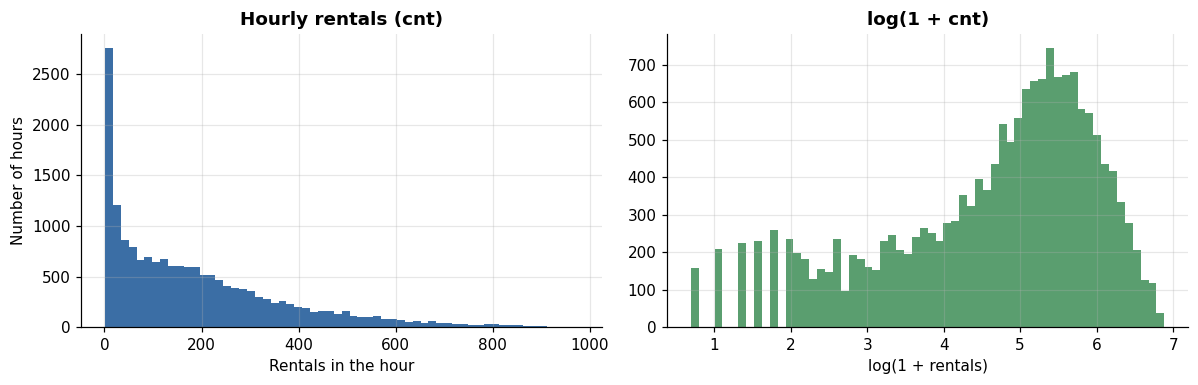

count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0

Skewness: 1.28
Share of hours with fewer than 10 rentals: 10.5%


In [8]:
# Distribution of the target on the raw and the log scale (the log scale shows how skewed demand is)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(eda.cnt, bins=60, color='#3b6ea5')
axes[0].set_title('Hourly rentals (cnt)')
axes[0].set_xlabel('Rentals in the hour')
axes[0].set_ylabel('Number of hours')
axes[1].hist(np.log1p(eda.cnt), bins=60, color='#5a9e6f')
axes[1].set_title('log(1 + cnt)')
axes[1].set_xlabel('log(1 + rentals)')
fig.tight_layout()
save(fig, '01_target_distribution.png')
plt.show()

print(eda.cnt.describe().round(1).to_string())
print('\nSkewness:', round(eda.cnt.skew(), 2))
print('Share of hours with fewer than 10 rentals:', f'{(eda.cnt < 10).mean():.1%}')

Demand is **right-skewed**: the median hour has 142 rentals but the busiest hours reach almost 1,000. A lot of hours are close to zero (night time) and a smaller number are very busy (commute peaks). Because the errors of a model will naturally be bigger when demand is high, I report both RMSE (which punishes big misses) and MAE (typical miss), and RMSLE (percentage-like error) in the evaluation.

### 3.2 Growth and seasonality over time

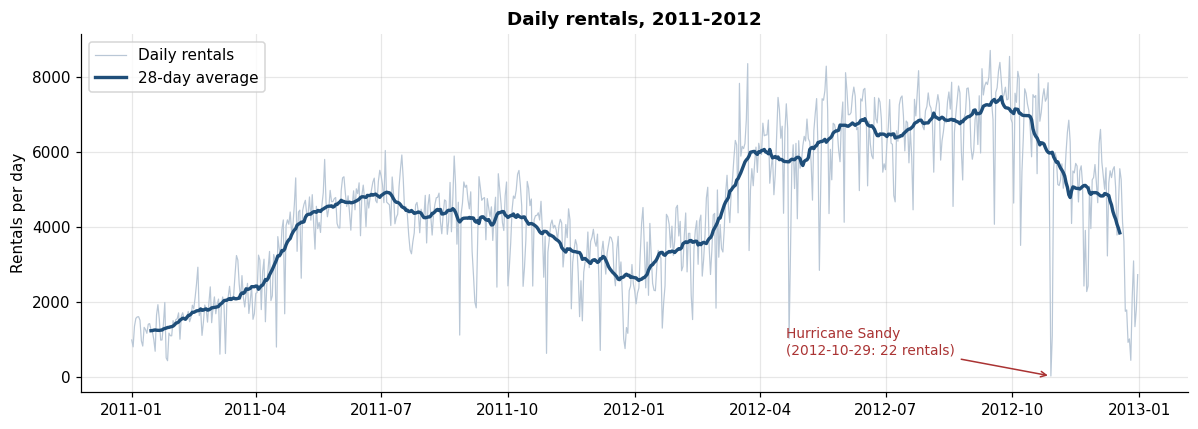

,avg rentals per hour,total rentals
year,,
2011,143.8,1243103
2012,234.7,2049576


Growth in average hourly demand 2011 -> 2012: 63%


In [9]:
# Long-term view: daily totals with a 28-day moving average, and Hurricane Sandy annotated
daily = days.set_index('dteday')
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily.cnt, color='#b9c7d6', lw=0.8, label='Daily rentals')
ax.plot(daily.index, daily.cnt.rolling(28, center=True).mean(), color='#1f4e79', lw=2.2, label='28-day average')
sandy = pd.Timestamp('2012-10-29')
ax.annotate('Hurricane Sandy\n(2012-10-29: 22 rentals)', xy=(sandy, 22), xytext=(pd.Timestamp('2012-04-20'), 600),
            arrowprops=dict(arrowstyle='->', color='#a33'), color='#a33', fontsize=9)
ax.set_title('Daily rentals, 2011-2012')
ax.set_ylabel('Rentals per day')
ax.legend(loc='upper left')
fig.tight_layout()
save(fig, '02_daily_rentals_over_time.png')
plt.show()

yearly = eda.groupby('year').cnt.agg(['mean', 'sum']).round(1)
yearly.columns = ['avg rentals per hour', 'total rentals']
display(yearly)
print(f'Growth in average hourly demand 2011 -> 2012: {yearly.iloc[1, 0] / yearly.iloc[0, 0] - 1:.0%}')

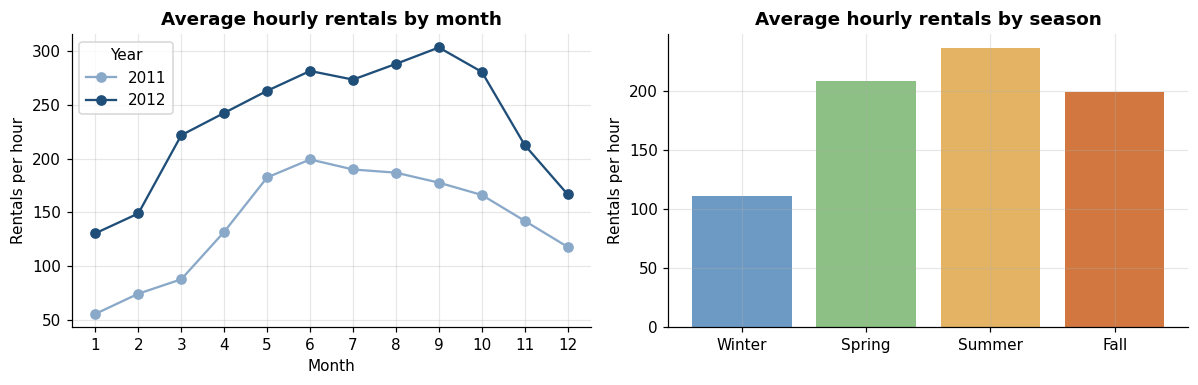

,avg rentals per hour
season_name,
Winter,111.1
Spring,208.3
Summer,236.0
Fall,198.9


In [10]:
# Seasonality: average demand by month (one line per year) and by season
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
month_avg = eda.groupby(['year', 'mnth']).cnt.mean().unstack(0)
month_avg.plot(ax=axes[0], marker='o', color=['#8aa9c9', '#1f4e79'])
axes[0].set_xticks(range(1, 13))
axes[0].set_title('Average hourly rentals by month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Rentals per hour')
axes[0].legend(title='Year')

order = ['Winter', 'Spring', 'Summer', 'Fall']
season_avg = eda.groupby('season_name').cnt.mean().reindex(order)
axes[1].bar(season_avg.index, season_avg.values, color=['#6c9ac4', '#8cc084', '#e4b363', '#d1773f'])
axes[1].set_title('Average hourly rentals by season')
axes[1].set_ylabel('Rentals per hour')
fig.tight_layout()
save(fig, '03_seasonality.png')
plt.show()
season_avg.round(1).to_frame('avg rentals per hour')

Two clear patterns:

* **Strong growth.** The system was about 63% busier in 2012 than in 2011, and the 2012 curve sits above 2011 in every month. Year is therefore a strong predictor, but also a danger: a model that has learned "2012 = high" cannot say what 2013 looks like without an assumption about further growth.
* **Strong seasonality.** Demand peaks from May to October (around 220-240 rentals per hour) and is lowest in January and February (around 95-115). By season (with the corrected labels), winter averages 111 rentals per hour versus 236 in summer, more than double, with spring (208) and fall (199) in between. The monthly curve is the more precise view and `season` is only a coarse summary of it.

### 3.3 Time of day: the most important pattern

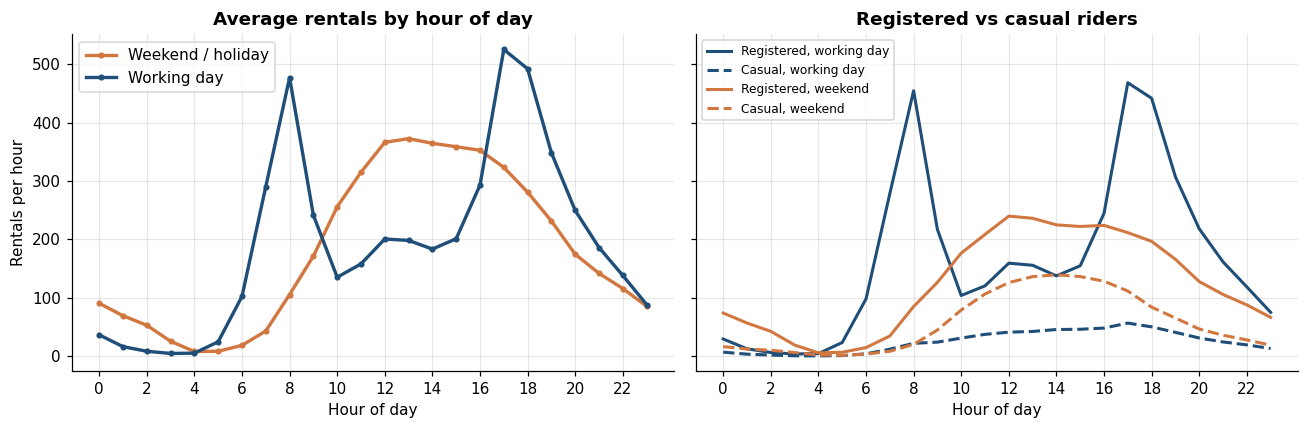

Busiest hour on a working day: 17 h  ( 525 rentals )
Busiest hour on a weekend/holiday: 13 h  ( 373 rentals )

Share of rentals by registered users:
workingday
weekend/holiday    0.68
working day        0.87


In [11]:
# Average demand for each hour of the day, split by working day vs weekend/holiday
profile = eda.groupby(['workingday', 'hr']).cnt.mean().unstack(0)
profile.columns = ['Weekend / holiday', 'Working day']
casual_reg = eda.groupby(['workingday', 'hr'])[['casual', 'registered']].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
profile.plot(ax=axes[0], color=['#d1773f', '#1f4e79'], lw=2.2, marker='o', ms=3)
axes[0].set_title('Average rentals by hour of day')
axes[0].set_xlabel('Hour of day')
axes[0].set_ylabel('Rentals per hour')
axes[0].set_xticks(range(0, 24, 2))

workday_users = casual_reg.loc[1]
weekend_users = casual_reg.loc[0]
axes[1].plot(workday_users.index, workday_users.registered, color='#1f4e79', lw=2, label='Registered, working day')
axes[1].plot(workday_users.index, workday_users.casual, color='#1f4e79', lw=2, ls='--', label='Casual, working day')
axes[1].plot(weekend_users.index, weekend_users.registered, color='#d1773f', lw=2, label='Registered, weekend')
axes[1].plot(weekend_users.index, weekend_users.casual, color='#d1773f', lw=2, ls='--', label='Casual, weekend')
axes[1].set_title('Registered vs casual riders')
axes[1].set_xlabel('Hour of day')
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(fontsize=8)
fig.tight_layout()
save(fig, '04_hourly_profile.png')
plt.show()

peaks = profile.idxmax()
print('Busiest hour on a working day:', peaks['Working day'], 'h  (', round(profile['Working day'].max()), 'rentals )')
print('Busiest hour on a weekend/holiday:', peaks['Weekend / holiday'], 'h  (', round(profile['Weekend / holiday'].max()), 'rentals )')
share = eda.groupby('workingday')[['casual', 'registered']].sum()
print('\nShare of rentals by registered users:')
print((share.registered / share.sum(axis=1)).rename({0: 'weekend/holiday', 1: 'working day'}).round(2).to_string())

This is the strongest structure in the data and it **depends on the type of day**:

* **Working days** show a double peak: around 08:00 (about 480 rentals per hour) and 17:00-18:00 (about 525), which are commuting hours, with a trough around midday.
* **Weekends and holidays** show a single broad hump from about 10:00 to 17:00 peaking around 13:00 (about 370).
* The commute peaks come almost entirely from **registered** users, while **casual** riders are a leisure group: on weekends they peak around 14:00 (about 140 casual rentals per hour), whereas on working days they are a small group (peak of about 57 at 17:00). Registered users make up 87% of working-day rentals and 68% of weekend rentals.

This is an *interaction* between `hr` and `workingday`. A purely linear model with separate effects for hour and day type cannot represent this shape properly, which is a reason to expect tree-based models to do better.

### 3.4 Weather

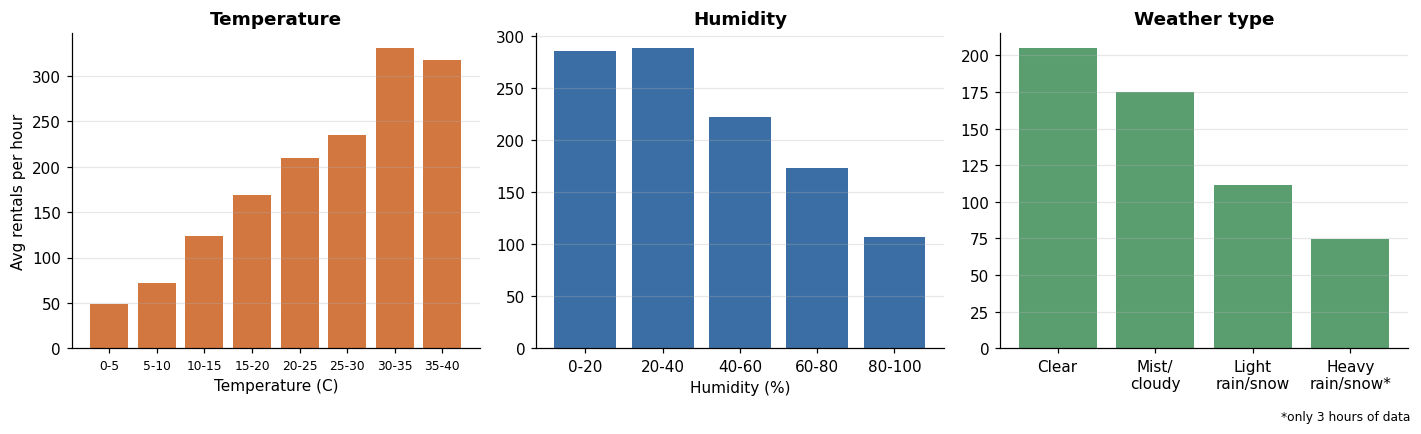

                 avg rentals per hour
weather_name                         
Clear                           205.0
Mist/cloudy                     175.0
Light rain/snow                 112.0
Heavy rain/snow                  74.0

          avg rentals per hour  hours
temp_c                               
(0, 5]                    49.0    193
(5, 10]                   72.0   1820
(10, 15]                 124.0   3428
(15, 20]                 168.0   2888
(20, 25]                 210.0   3215
(25, 30]                 235.0   3720
(30, 35]                 330.0   1757
(35, 40]                 318.0    356


In [12]:
# Demand against each weather variable (continuous variables are grouped into bins)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

# temperature
temp_bins = pd.cut(eda.temp_c, bins=range(-5, 45, 5))
temp_summary = eda.groupby(temp_bins).cnt.agg(['mean', 'count'])
temp_summary = temp_summary[temp_summary['count'] > 30]      # ignore bins with very few hours
axes[0].bar([f'{int(i.left)}-{int(i.right)}' for i in temp_summary.index], temp_summary['mean'], color='#d1773f')
axes[0].set_title('Temperature')
axes[0].set_xlabel('Temperature (C)')
axes[0].set_ylabel('Avg rentals per hour')
axes[0].tick_params(axis='x', labelsize=8)

# humidity
hum_bins = pd.cut(eda.hum_pct, bins=[0, 20, 40, 60, 80, 100], include_lowest=True)
hum_summary = eda.groupby(hum_bins).cnt.mean()
axes[1].bar([f'{int(i.left)}-{int(i.right)}' for i in hum_summary.index], hum_summary.values, color='#3b6ea5')
axes[1].set_title('Humidity')
axes[1].set_xlabel('Humidity (%)')

# weather type
weather_summary = eda.groupby('weather_name').cnt.mean().reindex(['Clear', 'Mist/cloudy', 'Light rain/snow', 'Heavy rain/snow'])
axes[2].bar(['Clear', 'Mist/\ncloudy', 'Light\nrain/snow', 'Heavy\nrain/snow*'], weather_summary.values, color='#5a9e6f')
axes[2].set_title('Weather type')
for ax in axes:
    ax.grid(axis='x', visible=False)
fig.text(0.99, -0.02, '*only 3 hours of data', ha='right', fontsize=8)
fig.tight_layout()
save(fig, '05_weather_effects.png')
plt.show()

print(weather_summary.round(0).to_frame('avg rentals per hour').to_string())
print()
print(temp_summary['mean'].round(0).rename('avg rentals per hour').to_frame().assign(hours=temp_summary['count']).to_string())

Warmer, drier, clearer hours have more rentals:

* Demand rises steadily with temperature: about 49 rentals per hour below 5 C, 124 at 10-15 C, 235 at 25-30 C and about 330 at 30-35 C. The small drop above 35 C rests on few hours.
* Humidity matters mainly when it is high: demand is highest at 20-40% humidity (about 288) and falls steadily above that, to about 107 at 80-100%.
* Rain or snow cuts average demand by almost half compared with clear weather (112 vs 205 rentals per hour).
* The heavy rain/snow bar rests on only three hours and should not be over-interpreted.

A caution before drawing conclusions: weather is **entangled with season and time of day**. Hot hours are in summer, and summer is also when the system was bigger and when people ride for leisure. The simple bar charts therefore overstate the "pure" effect of weather. This is why section 6.4 measures the contribution of whole groups of features in a model rather than eyeballing these charts.

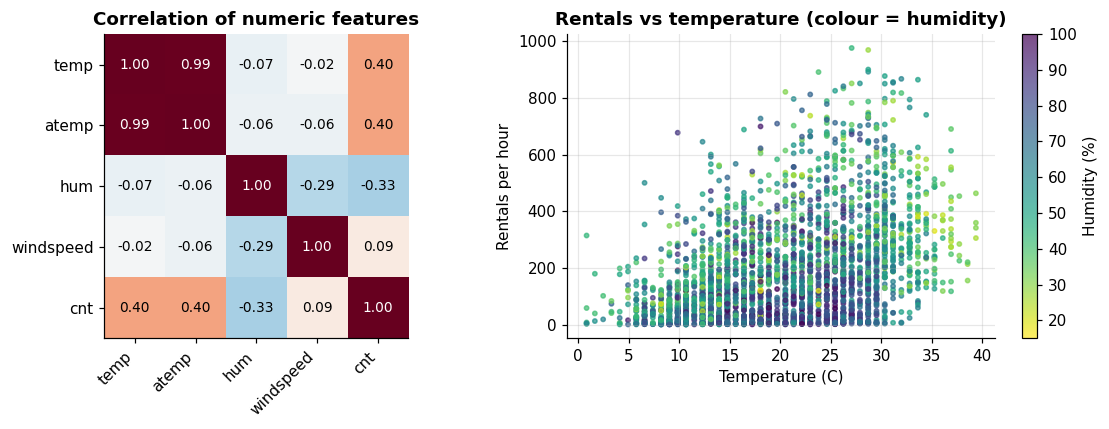

In [13]:
# Correlation matrix of the continuous variables, and demand vs temperature coloured by humidity
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

num = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
corr = hours[num].corr()
im = axes[0].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_xticks(range(len(num)), num, rotation=45, ha='right')
axes[0].set_yticks(range(len(num)), num)
for i in range(len(num)):
    for j in range(len(num)):
        axes[0].text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9,
                     color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
axes[0].grid(False)
axes[0].set_title('Correlation of numeric features')

sample = eda.sample(3000, random_state=RANDOM_STATE)    # a sample keeps the scatter plot readable
sc = axes[1].scatter(sample.temp_c, sample.cnt, c=sample.hum_pct, cmap='viridis_r', s=8, alpha=0.7)
axes[1].set_title('Rentals vs temperature (colour = humidity)')
axes[1].set_xlabel('Temperature (C)')
axes[1].set_ylabel('Rentals per hour')
fig.colorbar(sc, ax=axes[1], label='Humidity (%)')
fig.tight_layout()
save(fig, '06_correlations.png')
plt.show()

* `temp` and `atemp` ("feels-like" temperature) have a correlation of 0.99, so they carry essentially the same information. Keeping both would make linear coefficients unstable without adding anything, so **I drop `atemp`**.
* Temperature has the strongest linear correlation with demand (0.40), humidity is negative (-0.33), wind speed is nearly unrelated (0.09). These are modest correlations because the dominant driver, time of day, is *non-linear* (the double peak) and a correlation coefficient cannot see it.
* The scatter plot shows that for any temperature there is a very wide spread in demand, which is the hour-of-day effect again.

### 3.5 Weekday and holidays

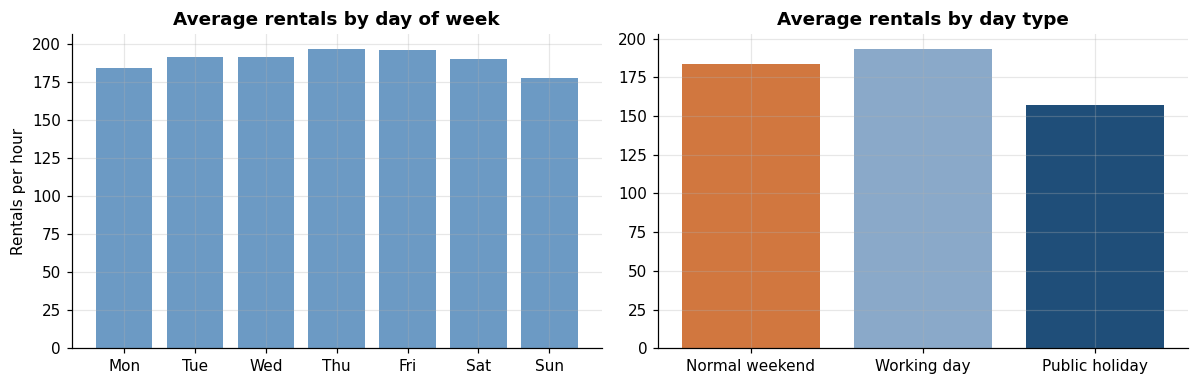

,mean,count
Normal weekend,183.9,5014
Working day,193.2,11865
Public holiday,156.9,500


Share of hours on a public holiday: 2.9%
weekday
Mon    184.0
Tue    191.0
Wed    191.0
Thu    196.0
Fri    196.0
Sat    190.0
Sun    177.0


In [14]:
# Demand by day of week and by day type (normal weekend / working day / public holiday)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
wk = eda.groupby('weekday').cnt.mean().rename(day_names).reindex(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[0].bar(wk.index, wk.values, color='#6c9ac4')
axes[0].set_title('Average rentals by day of week')
axes[0].set_ylabel('Rentals per hour')

hol = eda.groupby(['holiday', 'workingday']).cnt.agg(['mean', 'count']).round(1)
hol.index = ['Normal weekend' if (h == 0 and w == 0) else 'Public holiday' if h == 1 else 'Working day' for h, w in hol.index]
axes[1].bar(hol.index, hol['mean'], color=['#d1773f', '#8aa9c9', '#1f4e79'][:len(hol)])
axes[1].set_title('Average rentals by day type')
fig.tight_layout()
save(fig, '07_weekday_holiday.png')
plt.show()
display(hol)
print('Share of hours on a public holiday:', f'{(eda.holiday == 1).mean():.1%}')
print(wk.round(0).to_string())

Average demand is surprisingly similar across the days of the week, which hides the very different *shapes* of working-day and weekend demand shown in 3.3: the total is similar but it is spread differently across the day. Public holidays look like weekends in their shape and have somewhat lower totals than regular days. Holidays are rare (about 3% of hours), so the model has limited evidence about them.

### 3.6 Outlier analysis

Outliers can be data errors (which should be fixed or removed) or real events (which should be understood and usually kept). I look at them in two ways: a **univariate check** with the standard Tukey rule (a value more than 1.5 × IQR beyond the quartiles) on each continuous variable, and a **daily anomaly check** that compares each day with its surrounding month.

,outlier hours,share of hours
cnt,505.0,0.029
temp_c,0.0,0.000
hum_pct,0.0,0.000
wind,342.0,0.020
cnt (vs same hour & day type),130.0,0.007


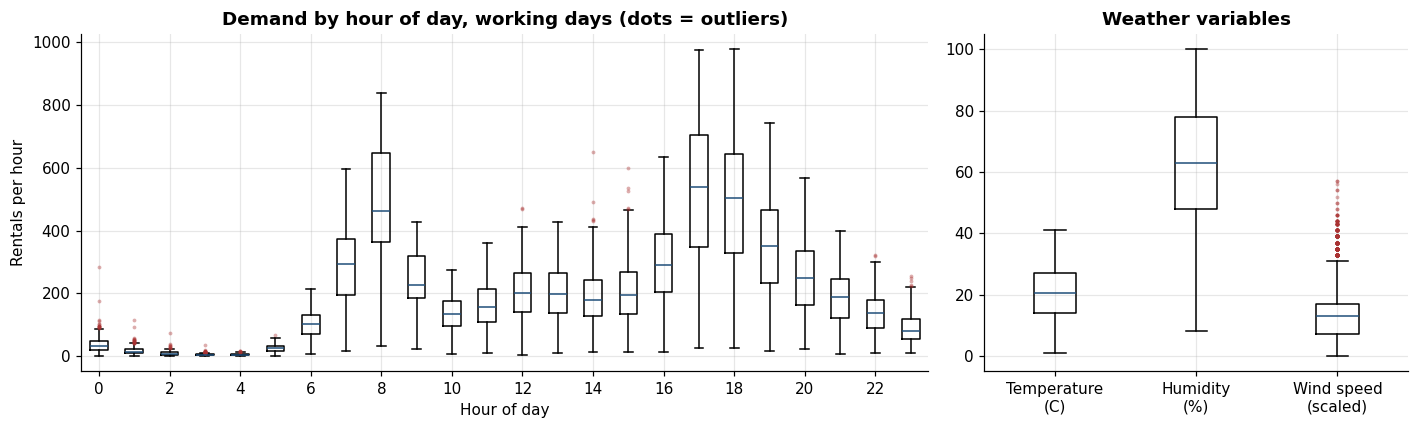

In [15]:
# Tukey rule: a value is an outlier if it lies more than 1.5 x IQR below the first or above the third quartile
def tukey_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)


numeric_cols = ['cnt', 'temp_c', 'hum_pct', 'wind']
outlier_summary = pd.DataFrame({
    'outlier hours': [tukey_outliers(eda[c]).sum() for c in numeric_cols],
    'share of hours': [tukey_outliers(eda[c]).mean() for c in numeric_cols],
}, index=numeric_cols)

# Demand is also judged against hours of the same kind (same hour and day type), because over the whole
# data the rule simply flags the normal busy commute hours
cnt_in_context = eda.groupby(['workingday', 'hr']).cnt.transform(tukey_outliers)
outlier_summary.loc['cnt (vs same hour & day type)'] = [cnt_in_context.sum(), cnt_in_context.mean()]
display(outlier_summary.round(3))

# Box plots: demand for each hour of a working day, and the three weather variables
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
workdays = eda[eda.workingday == 1]
axes[0].boxplot([workdays.loc[workdays.hr == hour, 'cnt'] for hour in range(24)], positions=range(24),
                flierprops=dict(marker='o', markersize=2.5, alpha=0.4, markerfacecolor='#a33', markeredgecolor='none'),
                medianprops=dict(color='#1f4e79'))
axes[0].set_xticks(range(0, 24, 2), range(0, 24, 2))
axes[0].set_title('Demand by hour of day, working days (dots = outliers)')
axes[0].set_xlabel('Hour of day')
axes[0].set_ylabel('Rentals per hour')
axes[1].boxplot([eda.temp_c, eda.hum_pct, eda.wind], labels=['Temperature\n(C)', 'Humidity\n(%)', 'Wind speed\n(scaled)'],
                flierprops=dict(marker='o', markersize=2.5, alpha=0.4, markerfacecolor='#a33', markeredgecolor='none'),
                medianprops=dict(color='#1f4e79'))
axes[1].set_title('Weather variables')
fig.tight_layout()
save(fig, '07b_outliers_boxplots.png')
plt.show()

**Reading the univariate check.**

* **Demand:** over the whole data set the Tukey rule flags 505 hours (2.9%), but when each hour is compared only with hours of the same kind (same hour of day and day type) just 130 (0.7%) are flagged. So most of the "outliers" are simply the normal busy commute hours, not anomalies. The box plot shows the spread of demand is widest at the commute peaks (the whiskers reach almost 1,000 rentals at 17:00), so even very busy rush hours are not outliers; the dots (unusually busy hours for their time of day) are mostly late-night and early-afternoon hours.
* **Temperature:** no outliers.
* **Wind speed:** 342 hours (2.0%) have unusually strong wind. These are plausible weather readings, so I keep them.
* **Humidity:** the 22 hours at exactly 0% were the only values flagged before the cleaning in section 2.1. After imputation there are none.

No hourly value looks like a data error apart from the humidity zeros that were already fixed. The next check looks at whole days.

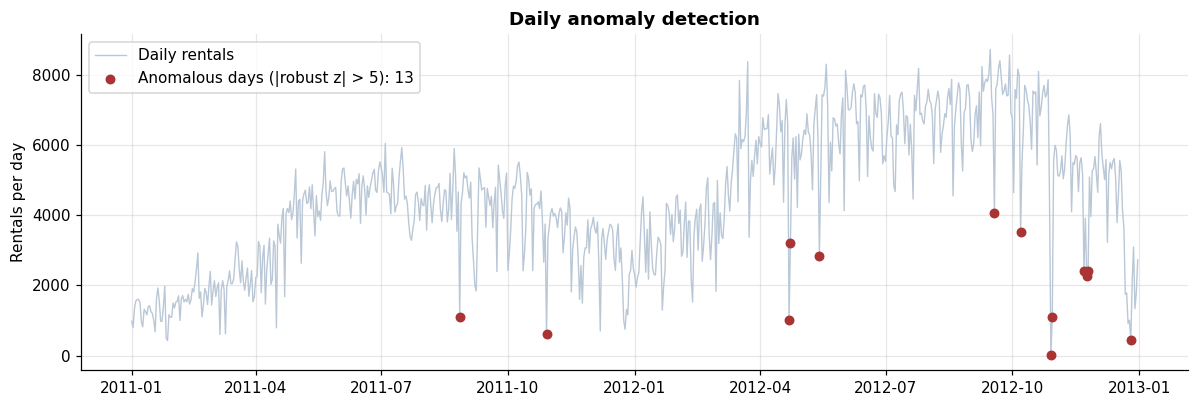

,cnt,holiday,robust_z,weekday,weather
dteday,,,,,
2012-10-29,22,0,-10.3,Mon,Light rain/snow
2012-04-22,1027,0,-8.9,Sun,Light rain/snow
2012-10-30,1096,0,-8.5,Tue,Mist/cloudy
2012-10-07,3510,0,-6.8,Sun,Mist/cloudy
2012-05-14,2843,0,-6.1,Mon,Mist/cloudy
2012-09-18,4073,0,-6.0,Tue,Mist/cloudy
2011-10-29,627,0,-5.9,Sat,Light rain/snow
2011-08-27,1115,0,-5.8,Sat,Mist/cloudy
2012-11-24,2277,0,-5.4,Sat,Clear


4 of the 13 anomalous days had rain or snow; public holidays among them: 1; all below the local level: True


In [16]:
# Daily anomalies: compare each day with the centred 29-day rolling median, then standardise the gaps with a
# robust z-score (median / MAD) that a few extreme days cannot distort
daily_cnt = days.set_index('dteday')['cnt']
gap = daily_cnt - daily_cnt.rolling(29, center=True, min_periods=15).median()
mad = (gap - gap.median()).abs().median()
robust_z = 0.6745 * (gap - gap.median()) / mad

flagged = robust_z.abs() > 5
anomalies = days.set_index('dteday').loc[flagged, ['cnt', 'weathersit', 'holiday']].copy()
anomalies['robust_z'] = robust_z[flagged].round(1)
anomalies['weekday'] = anomalies.index.strftime('%a')
anomalies['weather'] = anomalies['weathersit'].map(weather_names)
anomalies = anomalies.drop(columns='weathersit').sort_values('robust_z')

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily_cnt.index, daily_cnt, color='#b9c7d6', lw=0.9, label='Daily rentals')
ax.scatter(anomalies.index, anomalies['cnt'], color='#a33', s=30, zorder=3, label=f'Anomalous days (|robust z| > 5): {len(anomalies)}')
ax.set_title('Daily anomaly detection')
ax.set_ylabel('Rentals per day')
ax.legend(loc='upper left')
fig.tight_layout()
save(fig, '07c_daily_anomalies.png')
plt.show()

display(anomalies)
print(f'{(anomalies.weather.isin(["Light rain/snow", "Heavy rain/snow"])).sum()} of the {len(anomalies)} anomalous days had rain or snow; '
      f'public holidays among them: {(anomalies.holiday == 1).sum()}; all below the local level: {bool((anomalies.robust_z < 0).all())}')

**Reading the daily anomaly check.** Thirteen days have demand far from the level of their surrounding month, and **all thirteen are far *below* normal**. They are real events, not recording errors:

* **Hurricane Sandy:** 29 October 2012 (22 rentals, the lowest of the whole data set) and 30 October 2012.
* **Thanksgiving and Christmas periods:** 22, 24 and 25 November and 26 December 2012. Only one of the 13 days (Thanksgiving Day, 22 November) is flagged as a public holiday in the data.
* **Rain or snow:** four of the 13 days have the rain/snow weather category (29 October 2011, 22 April 2012, 29 October 2012 and 26 December 2012). 27 August 2011 is also on the list; it coincides with Hurricane Irene reaching the D.C. area, although the data labels the weather as only misty.
* **Unexplained:** 23 April, 14 May, 18 September and 7 October 2012 are ordinary-looking days with no cause visible in the data (possibly local events or system problems), so I cannot say why demand was low.

**Decision: keep all of them.** They are genuine behaviour that a forecasting model will meet in practice, and deleting them would make the model look better than it is. Because a few extreme days can dominate a squared-error metric, I report **MAE alongside RMSE**, and I look at how the model handles these days in the error analysis (section 6.3).

### 3.7 EDA summary

| Finding | Evidence | Consequence for modelling |
|---|---|---|
| Time of day is the dominant driver, and its shape depends on working day vs weekend | Double commute peak vs single midday hump | Need an `hr` x `workingday` interaction: tree models, or engineered features |
| Strong year-on-year growth (+63%) and seasonality | Monthly curves for 2011 and 2012 | Keep `yr` and `mnth`; split train/test **by time**, not at random |
| Weather matters, partly through season | Temperature, humidity and rain effects | Keep `temp`, `hum`, `weathersit`; drop `atemp` (0.99 correlated with `temp`) |
| `casual` + `registered` = target | Exact in every row | **Exclude both** as features (leakage) |
| Rare categories and one bad sensor day | 3 heavy-weather hours; 22 zero-humidity hours | Humidity imputed (section 2.1); heavy-weather hours kept |
| Outliers are real events, not errors | Storm, holiday and Hurricane Sandy days (section 3.6) | Keep them; use MAE next to RMSE; check them in the error analysis |

## 4. Data preparation and feature engineering

**Features used** (all known in advance for a forecast, since weather forecasts are available):

| Group | Columns |
|---|---|
| Calendar | `yr`, `mnth`, `weekday`, `holiday`, `workingday`, `season` |
| Time of day | `hr` |
| Weather | `weathersit`, `temp`, `hum`, `windspeed` |
| **Engineered** (new, built from the raw columns) | `hr_sin`, `hr_cos` (cyclical hour), `is_weekend`, `commute_hour` |

**Feature engineering.** The EDA showed that demand depends on the hour of day in a circular way (23:00 and 00:00 are neighbours) and that the working-day commute peaks are an interaction between hour and day type. Three engineered variables express this directly:

* `hr_sin`, `hr_cos`: the hour mapped onto a circle, so that the model sees that the end of the day is next to the start of the next one.
* `is_weekend`: Saturday or Sunday, separate from `workingday`, which also excludes public holidays.
* `commute_hour`: 1 on a working day between 07:00-09:59 or 16:00-19:59 (the two peaks from section 3.3), otherwise 0. This turns the hour × working-day interaction into a single flag.

**Excluded:** `instant` (row counter), `dteday` (the calendar information is already in the other columns), `atemp` (duplicate of `temp`), and `casual` and `registered` (parts of the target).

**Train/test split, by time.** Rental counts in consecutive hours are strongly related. A random split would put the hour *before* and the hour *after* a test row into the training set, which makes the task artificially easy and gives overly optimistic scores. A forecasting model is always used on the *future*, so I train on everything before **1 October 2012** (21 months) and test on **October-December 2012** (3 months). Model tuning uses forward-chaining `TimeSeriesSplit` cross-validation inside the training set only.

In [17]:
COMMUTE_HOURS = [7, 8, 9, 16, 17, 18, 19]     # the two rush-hour windows seen in section 3.3


def add_features(df):
    # Create the engineered variables from the raw columns
    out = df.copy()
    # Cyclical hour: puts 23:00 next to 00:00, which the raw number 0-23 cannot express
    out['hr_sin'] = np.sin(2 * np.pi * out['hr'] / 24)
    out['hr_cos'] = np.cos(2 * np.pi * out['hr'] / 24)
    # Weekend flag (Sunday = 0, Saturday = 6)
    out['is_weekend'] = out['weekday'].isin([0, 6]).astype(int)
    # Commute-hour flag: the hour x day-type interaction from the EDA, made explicit
    out['commute_hour'] = ((out['workingday'] == 1) & out['hr'].isin(COMMUTE_HOURS)).astype(int)
    return out


hours = add_features(hours.sort_values('instant').reset_index(drop=True))

# Quick sanity check that the new flag separates busy from quiet hours
print('Average rentals per hour by commute_hour flag:')
print(hours.groupby('commute_hour').cnt.mean().round(1).rename({0: 'not a commute hour', 1: 'commute hour'}).to_string())

TARGET = 'cnt'
BASE_FEATURES = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']
ENGINEERED_FEATURES = ['hr_sin', 'hr_cos', 'is_weekend', 'commute_hour']
FEATURES = BASE_FEATURES + ENGINEERED_FEATURES
CATEGORICAL = ['season', 'mnth', 'hr', 'weekday', 'weathersit']     # one-hot encoded for the linear model

# Time-based split: train on the past, test on the most recent three months
cutoff = pd.Timestamp('2012-10-01')
train = hours[hours.dteday < cutoff]
test = hours[hours.dteday >= cutoff]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f'Train: {len(train):,} hours  ({train.dteday.min().date()} to {train.dteday.max().date()})')
print(f'Test : {len(test):,} hours  ({test.dteday.min().date()} to {test.dteday.max().date()})')
print(f'Mean demand  train: {y_train.mean():.1f} | test: {y_test.mean():.1f}')

Average rentals per hour by commute_hour flag:
commute_hour
not a commute hour    141.4
commute hour          381.3
Train: 15,211 hours  (2011-01-01 to 2012-09-30)
Test : 2,168 hours  (2012-10-01 to 2012-12-31)
Mean demand  train: 185.2 | test: 219.2


## 5. Baseline modelling and evaluation metric

### Evaluation metric and why

| Metric | Role | Why it is used |
|---|---|---|
| **RMSE** (bikes per hour) | **Primary metric**: used to tune the models (cross-validation) and to choose the baseline | It is in the same unit as the target, so it reads directly as "the typical size of a miss". It squares the errors before averaging, so it punishes large misses more than small ones, which matches the operator's problem: being 300 bikes short at the 17:00 peak costs far more than being 10 bikes off at night. |
| MAE | Secondary | The average absolute miss. Easy to explain and less dominated by a few extreme days (storms, holidays), so comparing it with RMSE shows how much the large errors matter. |
| R² | Context | The share of the variation in demand that the model explains compared with always predicting the mean: 0 is no better than the mean, 1 is perfect, and it can be negative. |
| RMSLE | Check | Error on a log scale, i.e. a *relative* error. RMSE is dominated by the busy hours, so RMSLE shows whether the model is also good at quiet hours. |

Accuracy, precision and recall do not apply because the target is a count, not a class. I avoid MAPE (percentage error) because many hours have very few rentals, where a miss of a few bikes becomes a huge percentage.

### The models

I compare a ladder of models from very simple to moderately powerful, so that each step of complexity has to *earn* its place:

1. **Overall mean**: predict the training average every time (the "do nothing smart" floor).
2. **Typical-day lookup**: the average demand for the same hour, day type and year. No machine learning, just a table. This is what a planner could do with a spreadsheet.
3. **Linear regression** with one-hot encoded calendar fields: the simplest ML model.
4. **Random forest** (an ensemble of decision trees, the topic of this module): it can capture the hour x working-day interaction and non-linear weather effects without manual feature engineering.
5. **Gradient boosting** (`HistGradientBoostingRegressor`): a second ensemble technique, where trees are built one after another to correct the errors of the previous ones.

The ensemble with the lowest test RMSE becomes the baseline model carried forward.

All metrics are computed on the October-December 2012 test period. Negative predictions are clipped at zero because a rental count cannot be negative.

In [18]:
def evaluate(name, y_true, y_pred):
    # Return all four metrics for one model as a dictionary
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    return {
        'model': name,
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'RMSLE': np.sqrt(mean_squared_log_error(y_true, y_pred)),
    }


results = []
predictions = {}

# 1. overall mean: the floor every model has to beat
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
predictions['Overall mean'] = dummy.predict(X_test)

# 2. typical-day lookup (hour x working day x year)
keys = ['yr', 'workingday', 'hr']
lookup = train.groupby(keys)[TARGET].mean().rename('pred').reset_index()
predictions['Typical-day lookup'] = test[keys].merge(lookup, on=keys, how='left').pred.fillna(y_train.mean()).values

# 3. linear regression: one-hot encode the categorical codes, pass the numeric columns through
prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)], remainder='passthrough')
linear = Pipeline([('prep', prep), ('model', LinearRegression())]).fit(X_train, y_train)
predictions['Linear regression'] = linear.predict(X_test)

for name, pred in predictions.items():
    results.append(evaluate(name, y_test, pred))
pd.DataFrame(results).round(3)

,model,RMSE,MAE,R2,RMSLE
0,Overall mean,204.428,156.868,-0.028,1.500
1,Typical-day lookup,114.191,71.624,0.679,0.640
2,Linear regression,108.049,78.701,0.713,0.982


Now the two ensembles. First the random forest. I tune two settings with forward-chaining cross-validation on the training period only: the minimum leaf size (smoother vs more detailed trees) and the share of features tried at each split. The test period is not touched during tuning.

In [19]:
# Forward-chaining cross-validation: each fold trains on the past and validates on the period right after it
tscv = TimeSeriesSplit(n_splits=5)
rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={'min_samples_leaf': [1, 3, 5, 10], 'max_features': [0.5, 0.8, 1.0]},
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=1,
)
rf_search.fit(X_train, y_train)
rf = rf_search.best_estimator_

print('Best parameters:', rf_search.best_params_)
print('Cross-validated RMSE (training period only):', round(-rf_search.best_score_, 1))
cv = pd.DataFrame(rf_search.cv_results_)[['param_min_samples_leaf', 'param_max_features', 'mean_test_score']]
cv['CV RMSE'] = -cv.pop('mean_test_score')
cv.sort_values('CV RMSE').head(6).round(1).reset_index(drop=True)

Best parameters: {'max_features': 0.8, 'min_samples_leaf': 1}
Cross-validated RMSE (training period only): 77.8


,param_min_samples_leaf,param_max_features,CV RMSE
0,1,0.8,77.8
1,1,0.5,78.3
2,1,1.0,78.6
3,3,0.8,79.0
4,3,1.0,79.7
5,3,0.5,79.8


Then gradient boosting, tuned the same way (learning rate, number of boosting rounds and minimum leaf size).

In [20]:
# Same tuning procedure for gradient boosting
hgb_search = GridSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid={'learning_rate': [0.05, 0.1], 'max_iter': [200, 400], 'min_samples_leaf': [20, 50]},
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=1,
)
hgb_search.fit(X_train, y_train)
hgb = hgb_search.best_estimator_
print('Best parameters:', hgb_search.best_params_)
print('Cross-validated RMSE (training period only):', round(-hgb_search.best_score_, 1))

predictions['Random forest'] = rf.predict(X_test)
predictions['Gradient boosting'] = hgb.predict(X_test)

results = [evaluate(name, y_test, pred) for name, pred in predictions.items()]
scores = pd.DataFrame(results).set_index('model')
scores.round(3)

Best parameters: {'learning_rate': 0.1, 'max_iter': 400, 'min_samples_leaf': 20}
Cross-validated RMSE (training period only): 73.1


,RMSE,MAE,R2,RMSLE
model,,,,
Overall mean,204.428,156.868,-0.028,1.500
Typical-day lookup,114.191,71.624,0.679,0.640
Linear regression,108.049,78.701,0.713,0.982
Random forest,68.342,43.122,0.885,0.454
Gradient boosting,63.625,39.306,0.900,0.495


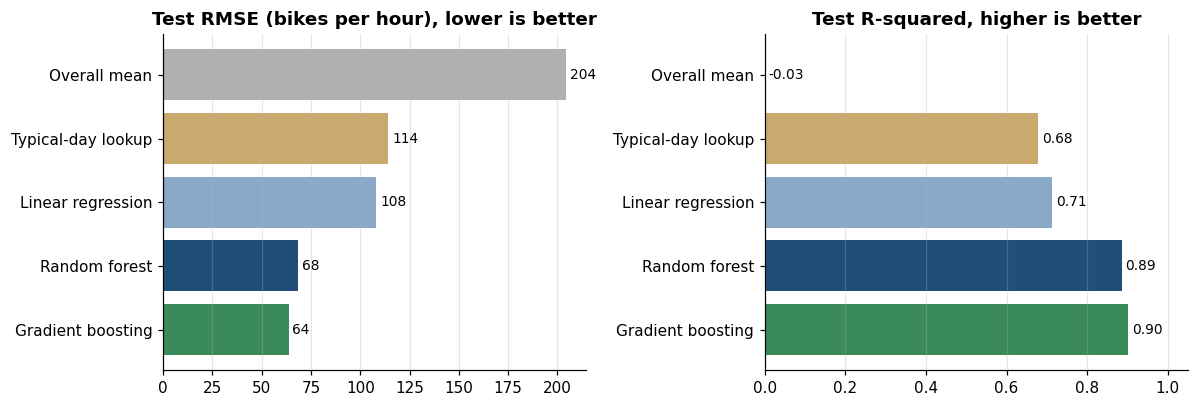

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ['#b0b0b0', '#c9a96e', '#8aa9c9', '#1f4e79', '#3b8a5a']
axes[0].barh(scores.index[::-1], scores.RMSE[::-1], color=colors[::-1])
axes[0].set_title('Test RMSE (bikes per hour), lower is better')
for i, v in enumerate(scores.RMSE[::-1]):
    axes[0].text(v + 2, i, f'{v:.0f}', va='center', fontsize=9)
axes[0].grid(axis='y', visible=False)

axes[1].barh(scores.index[::-1], scores.R2[::-1], color=colors[::-1])
axes[1].set_title('Test R-squared, higher is better')
for i, v in enumerate(scores.R2[::-1]):
    axes[1].text(max(v, 0) + 0.01, i, f'{v:.2f}', va='center', fontsize=9)
axes[1].set_xlim(0, 1.05)
axes[1].grid(axis='y', visible=False)
fig.tight_layout()
save(fig, '08_model_comparison.png')
plt.show()

**How to read these results (interpretation of the metrics).**

* **RMSE, the primary metric.** The best model (gradient boosting) has an RMSE of about **64 bikes per hour**. Average demand in the test period is 219 bikes per hour, so a typical forecast is off by roughly 29% of demand. That is **44% lower than the typical-day lookup (114)**, the strongest simple benchmark, and about 69% lower than predicting the mean (204).
* **MAE.** The average absolute miss is about **39 bikes per hour (18% of average demand)**. RMSE (64) is much larger than MAE (39), which tells us that a minority of large misses dominate the squared error. The error analysis in section 6 shows that these are mainly holiday days.
* **R² = 0.90.** The model explains about 90% of the variation in hourly demand. The overall mean has an R² slightly below zero (-0.03) because the test period is busier than the training average: the system kept growing.
* **Linear regression** (RMSE 108, R² 0.71) is only a little better than the lookup table (RMSE 114, R² 0.68) and has a larger average miss (MAE 79 vs 72). Demand has interactions (hour × day type) that a straight-line model cannot capture, which is why the tree ensembles do so much better.
* **Random forest vs gradient boosting.** Gradient boosting is better on RMSE (64 vs 68), MAE (39 vs 43) and R² (0.90 vs 0.89), so it is the baseline carried forward. The random forest is a little better on RMSLE (0.45 vs 0.50), i.e. on relative error in quiet hours. The gap between the two ensembles is small and comes from one three-month test window, so I treat them as close.

## 6. Model evaluation and error analysis

Both ensembles are far ahead of the baselines. **Gradient boosting wins on RMSE, MAE and R², so it is the baseline model I carry forward.** (The random forest is slightly better on RMSLE, i.e. on relative error at quiet hours, so the two are close.) This section checks where the chosen model is right, where it is wrong, and what it relies on.

### 6.1 Predicted vs actual

Model carried forward: Gradient boosting


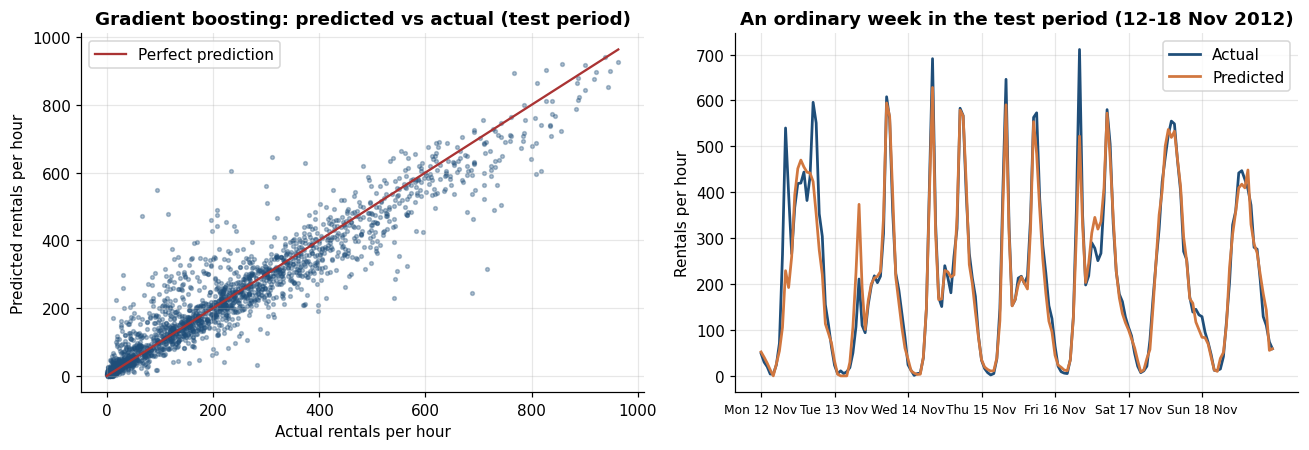

In [22]:
# Pick the model with the lowest test RMSE (the primary metric) and collect its predictions
best_name = scores.RMSE.idxmin()
best_model = {'Random forest': rf, 'Gradient boosting': hgb}[best_name]
print('Model carried forward:', best_name)

res = test[['dteday', 'hr', 'holiday', 'workingday', 'cnt']].copy()
res['pred'] = np.clip(predictions[best_name], 0, None)
res['error'] = res.pred - res.cnt
res['abs_error'] = res.error.abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(res.cnt, res.pred, s=6, alpha=0.35, color='#1f4e79')
lim = max(res.cnt.max(), res.pred.max())
axes[0].plot([0, lim], [0, lim], color='#a33', lw=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual rentals per hour')
axes[0].set_ylabel('Predicted rentals per hour')
axes[0].set_title(f'{best_name}: predicted vs actual (test period)')
axes[0].legend()

week = res[(res.dteday >= '2012-11-12') & (res.dteday < '2012-11-19')].reset_index(drop=True)
axes[1].plot(week.index, week.cnt, color='#1f4e79', lw=1.8, label='Actual')
axes[1].plot(week.index, week.pred, color='#d1773f', lw=1.8, label='Predicted')
axes[1].set_xticks(range(0, len(week), 24), [d.strftime('%a %d %b') for d in week.dteday[::24]], fontsize=8)
axes[1].set_title('An ordinary week in the test period (12-18 Nov 2012)')
axes[1].set_ylabel('Rentals per hour')
axes[1].legend()
fig.tight_layout()
save(fig, '09_predicted_vs_actual.png')
plt.show()

### 6.2 Where does the model make its errors?

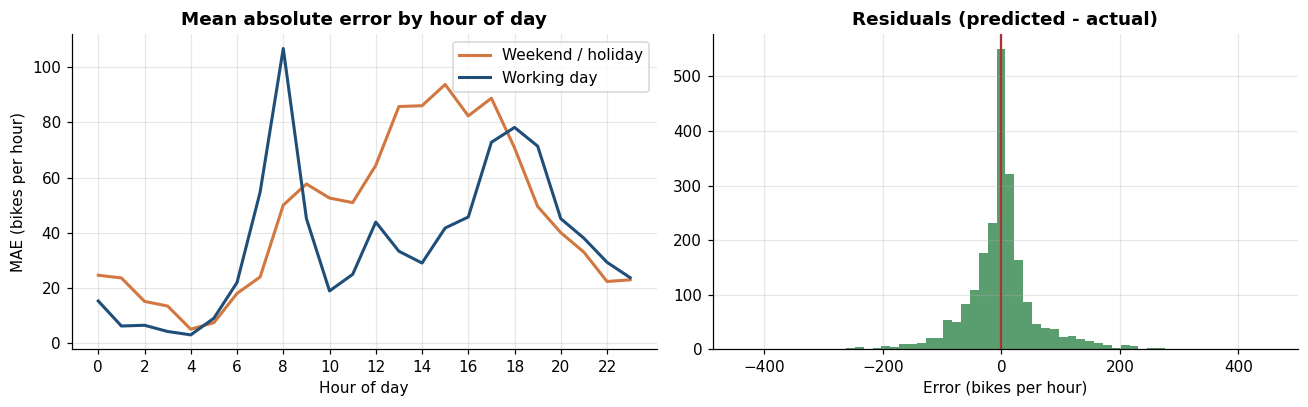

Test-period mean demand: 219.2 rentals per hour
Model MAE              : 39.3 (18% of mean demand)
Median absolute error  : 21.6
Bias (mean residual)   : 0.2 (positive = model over-predicts on average)
Hours within 50 rentals of actual: 74%
MAE in commute peak hours (8, 17, 18): 80.5
MAE in all other hours               : 33.4
MAE overnight (hours 0-5)          : 10.0


In [23]:
# Error by hour of day (working day vs weekend) and the distribution of the residuals
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
mae_hr = res.groupby(['workingday', 'hr']).abs_error.mean().unstack(0)
mae_hr.columns = ['Weekend / holiday', 'Working day']
mae_hr.plot(ax=axes[0], color=['#d1773f', '#1f4e79'], lw=2)
axes[0].set_title('Mean absolute error by hour of day')
axes[0].set_xlabel('Hour of day')
axes[0].set_ylabel('MAE (bikes per hour)')
axes[0].set_xticks(range(0, 24, 2))

axes[1].hist(res.error, bins=60, color='#5a9e6f')
axes[1].axvline(0, color='#a33')
axes[1].set_title('Residuals (predicted - actual)')
axes[1].set_xlabel('Error (bikes per hour)')
fig.tight_layout()
save(fig, '10_error_by_hour.png')
plt.show()

print('Test-period mean demand:', round(res.cnt.mean(), 1), 'rentals per hour')
print('Model MAE              :', round(res.abs_error.mean(), 1), f'({res.abs_error.mean() / res.cnt.mean():.0%} of mean demand)')
print('Median absolute error  :', round(res.abs_error.median(), 1))
print('Bias (mean residual)   :', round(res.error.mean(), 1), '(positive = model over-predicts on average)')
print('Hours within 50 rentals of actual:', f'{(res.abs_error <= 50).mean():.0%}')
peak = res[res.hr.isin([8, 17, 18])]
print('MAE in commute peak hours (8, 17, 18):', round(peak.abs_error.mean(), 1))
print('MAE in all other hours               :', round(res.drop(peak.index).abs_error.mean(), 1))
print('MAE overnight (hours 0-5)          :', round(res[res.hr <= 5].abs_error.mean(), 1))

The chosen model is essentially unbiased (on average it over-predicts by only 0.2 bikes per hour). Its median error is 22 bikes per hour and 74% of hours are predicted to within 50 rentals. The mean absolute error is 39 bikes, which is 18% of the average test-period demand of 219.

Errors are largest in the **commute peaks** (hours 8, 17 and 18, MAE of about 81 bikes versus 33 in all other hours and 10 overnight). That is expected: these are the busiest hours, so a given percentage error is a larger number of bikes, and they are the hours most sensitive to the exact conditions of the day.

### 6.3 The biggest misses: holidays, not the hurricane

Daily totals make the large errors easy to see. October 2012 contained an extreme event, **Hurricane Sandy (29-30 October)**, so I check how the model handled it as well as which days it got most wrong.

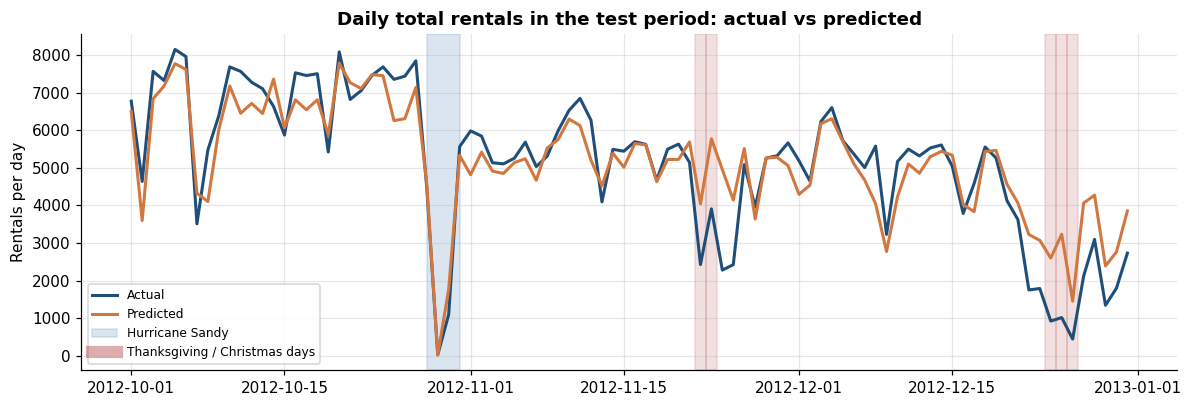

Largest daily errors:


,actual,predicted,holiday,workingday,error,weekday
dteday,,,,,,
2012-11-24,2277,4954.0,0,0,2677.0,Sat
2012-12-25,1013,3233.0,1,0,2220.0,Tue
2012-12-27,2114,4063.0,0,1,1949.0,Thu
2012-11-23,3910,5775.0,0,1,1865.0,Fri
2012-11-25,2424,4144.0,0,0,1720.0,Sun
2012-12-24,920,2597.0,0,1,1677.0,Mon
2012-11-22,2425,4043.0,1,0,1618.0,Thu
2012-12-08,5582,4044.0,0,0,-1538.0,Sat


Hurricane Sandy days (actual vs predicted daily rentals):


,actual,predicted,error
dteday,,,
2012-10-28,4459,4559.0,100.0
2012-10-29,22,15.0,-7.0
2012-10-30,1096,1765.0,669.0
2012-10-31,5566,5332.0,-234.0


RMSE, full test period                           : 63.6
RMSE, excluding the 5 Thanksgiving/Christmas days: 59.6
R2,   full test period                           : 0.9
R2,   excluding the 5 days                       : 0.914

How the dataset flags those days:
                holiday  workingday
Thu 2012-11-22        1           0
Fri 2012-11-23        0           1
Mon 2012-12-24        0           1
Tue 2012-12-25        1           0
Wed 2012-12-26        0           1


In [24]:
# Aggregate to daily totals to see which whole days the model gets most wrong
day_res = res.groupby('dteday').agg(actual=('cnt', 'sum'), predicted=('pred', 'sum'), holiday=('holiday', 'max'), workingday=('workingday', 'max'))
day_res['error'] = day_res.predicted - day_res.actual
day_res['weekday'] = day_res.index.strftime('%a')

holiday_period = pd.to_datetime(['2012-11-22', '2012-11-23', '2012-12-24', '2012-12-25', '2012-12-26'])

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(day_res.index, day_res.actual, color='#1f4e79', lw=2, label='Actual')
ax.plot(day_res.index, day_res.predicted, color='#d1773f', lw=2, label='Predicted')
ax.axvspan(pd.Timestamp('2012-10-28'), pd.Timestamp('2012-10-31'), color='#6c9ac4', alpha=0.25, label='Hurricane Sandy')
for holiday_date in holiday_period:
    ax.axvspan(holiday_date - pd.Timedelta(hours=12), holiday_date + pd.Timedelta(hours=12), color='#a33', alpha=0.15)
ax.plot([], [], color='#a33', alpha=0.4, lw=8, label='Thanksgiving / Christmas days')
ax.set_title('Daily total rentals in the test period: actual vs predicted')
ax.set_ylabel('Rentals per day')
ax.legend(loc='lower left', fontsize=8)
fig.tight_layout()
save(fig, '11_biggest_misses.png')
plt.show()

print('Largest daily errors:')
display(day_res.reindex(day_res.error.abs().sort_values(ascending=False).index).head(8).round(0))

print('Hurricane Sandy days (actual vs predicted daily rentals):')
display(day_res.loc['2012-10-28':'2012-10-31', ['actual', 'predicted', 'error']].round(0))

keep = ~res.dteday.isin(holiday_period)
print('RMSE, full test period                           :', round(np.sqrt(mean_squared_error(res.cnt, res.pred)), 1))
print('RMSE, excluding the 5 Thanksgiving/Christmas days:', round(np.sqrt(mean_squared_error(res.cnt[keep], res.pred[keep])), 1))
print('R2,   full test period                           :', round(r2_score(res.cnt, res.pred), 3))
print('R2,   excluding the 5 days                       :', round(r2_score(res.cnt[keep], res.pred[keep]), 3))

hol_flag = test.groupby('dteday')[['holiday', 'workingday']].max().loc[holiday_period]
hol_flag.index = hol_flag.index.strftime('%a %Y-%m-%d')
print('\nHow the dataset flags those days:')
print(hol_flag.to_string())

**Hurricane Sandy was handled well.** On 29 October the model predicted 15 rentals and the actual figure was 22. It did not need to "know" about the hurricane: that day's very high wind speed, 88% humidity and rain/snow weather category were enough to push the prediction to almost zero. The model was too high on 30 October (1,765 predicted vs 1,096 actual): the weather had already improved but rentals were still depressed, which is an after-effect that weather variables cannot see.

**The real weakness is holiday periods.** Seven of the eight largest daily errors in the test period are *over-predictions* on Thanksgiving weekend (22-25 November) or around Christmas (24, 25 and 27 December). For example, on Saturday 24 November the model predicted about 4,950 rentals and there were 2,277. (The eighth, 8 December, goes the other way: 5,582 actual vs 4,044 predicted, with no cause visible in the data.) The table at the end of the previous cell suggests why: the dataset's `holiday` flag only marks the official day (Thanksgiving Thursday and Christmas Day). The Friday after Thanksgiving, Christmas Eve and 26 December are all coded as ordinary *working days*, and the Saturday after Thanksgiving as an ordinary weekend, yet demand on those days is far below normal. On top of that, public holidays are only 2.9% of the hours in the data, so the model has just one Thanksgiving and one Christmas week (2011) to learn from. Removing just five of these days reduces the test RMSE from 63.6 to 59.6.

This is my hypothesis from the pattern in the errors and I have not yet tested it, but it points to a clear improvement for the next module: a "holiday period" feature that marks the days around the main holidays.

### 6.4 Which kinds of information does the model rely on?

Several features are strongly related to each other (`temp` and season, `season` and month, `workingday` and weekday), so ranking single columns is misleading: when one of two overlapping features is removed, the other covers for it. I therefore measure **groups** of related features. For each group the model is re-trained on the training period *without* it and evaluated on the same test period; the larger the increase in error, the more the model depends on that information. (I did not use permutation importance here because the test period lies entirely in 2012, so shuffling `yr` is meaningless.)

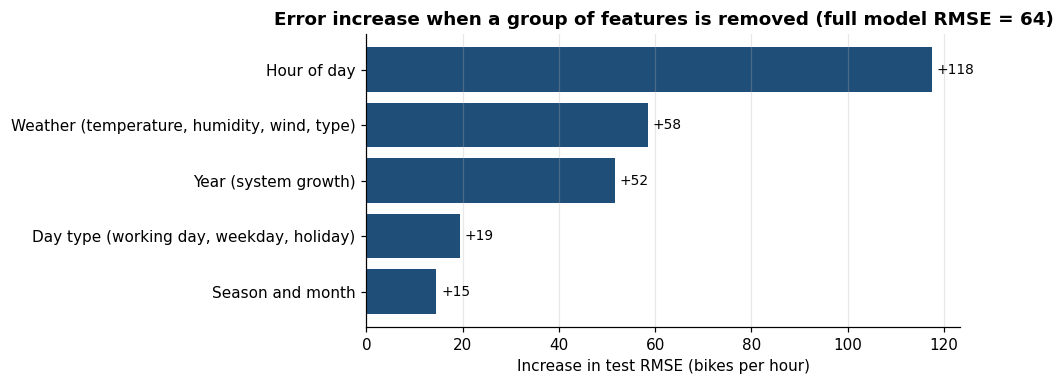

,group removed,test RMSE,test R2,RMSE increase
0,Hour of day,181.204,0.192,117.579
1,"Weather (temperature, humidity, wind, type)",122.060,0.633,58.435
2,Year (system growth),115.310,0.673,51.685
3,"Day type (working day, weekday, holiday)",83.074,0.830,19.448
4,Season and month,78.151,0.850,14.526


In [25]:
# Groups of related features (engineered columns go with the raw column they were built from)
groups = {
    'Hour of day': ['hr', 'hr_sin', 'hr_cos', 'commute_hour'],
    'Day type (working day, weekday, holiday)': ['workingday', 'weekday', 'holiday', 'is_weekend'],
    'Weather (temperature, humidity, wind, type)': ['temp', 'hum', 'windspeed', 'weathersit'],
    'Season and month': ['season', 'mnth'],
    'Year (system growth)': ['yr'],
}
full_rmse = np.sqrt(mean_squared_error(y_test, np.clip(hgb.predict(X_test), 0, None)))

rows = []
for name, cols in groups.items():
    # re-train without the group, then score on the same test period
    kept = [f for f in FEATURES if f not in cols]
    reduced_model = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **hgb_search.best_params_).fit(train[kept], y_train)
    reduced_pred = np.clip(reduced_model.predict(test[kept]), 0, None)
    rows.append({'group removed': name, 'test RMSE': np.sqrt(mean_squared_error(y_test, reduced_pred)),
                 'test R2': r2_score(y_test, reduced_pred)})
group_imp = pd.DataFrame(rows)
group_imp['RMSE increase'] = group_imp['test RMSE'] - full_rmse
group_imp = group_imp.sort_values('RMSE increase', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 3.6))
plot_data = group_imp.iloc[::-1]
ax.barh(plot_data['group removed'], plot_data['RMSE increase'], color='#1f4e79')
for i, v in enumerate(plot_data['RMSE increase']):
    ax.text(v + 1, i, f'+{v:.0f}', va='center', fontsize=9)
ax.set_title(f'Error increase when a group of features is removed (full model RMSE = {full_rmse:.0f})')
ax.set_xlabel('Increase in test RMSE (bikes per hour)')
ax.grid(axis='y', visible=False)
fig.tight_layout()
save(fig, '12_feature_group_importance.png')
plt.show()
group_imp.round(3)

**Hour of day is by far the most important information**: removing it drops the test R² from 0.90 to 0.19 and raises the RMSE by 118 bikes per hour. **Weather** is second (+58), followed by **year / system growth** (+52) and **day type** (+19). **Season and month** add the least (+15), because temperature already carries most of the seasonal information.

Two cautions. First, the year result is a warning about using the model in the future: without `yr` the model cannot know that 2012 was busier than 2011 and loses a lot of accuracy, so a forecast for 2013 needs an explicit assumption about continued growth. Second, these numbers come from one three-month test window (October-December), so they describe how the model behaves in autumn; weather may matter more in summer.

### 6.5 Did the feature engineering help?

To check that the engineered features earn their place, I re-train the linear model and the gradient-boosting model on the **raw features only** and compare them with the versions that use the engineered features (same settings, same test period).

In [26]:
# Refit both models on the raw columns only
linear_raw = Pipeline([
    ('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)], remainder='passthrough')),
    ('model', LinearRegression()),
]).fit(train[BASE_FEATURES], y_train)
hgb_raw = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **hgb_search.best_params_).fit(train[BASE_FEATURES], y_train)

feature_check = pd.DataFrame([
    evaluate('Linear regression, raw features', y_test, linear_raw.predict(test[BASE_FEATURES])),
    evaluate('Linear regression, + engineered features', y_test, predictions['Linear regression']),
    evaluate('Gradient boosting, raw features', y_test, hgb_raw.predict(test[BASE_FEATURES])),
    evaluate('Gradient boosting, + engineered features', y_test, predictions['Gradient boosting']),
]).set_index('model')
feature_check.round(3)

,RMSE,MAE,R2,RMSLE
model,,,,
"Linear regression, raw features",121.607,89.149,0.636,1.002
"Linear regression, + engineered features",108.049,78.701,0.713,0.982
"Gradient boosting, raw features",65.746,42.372,0.894,0.516
"Gradient boosting, + engineered features",63.625,39.306,0.900,0.495


The engineered features help both models:

* **Linear regression improves a lot**: RMSE 122 to 108, MAE 89 to 79 and R² 0.64 to 0.71. The `commute_hour` flag hands the linear model the hour × day-type interaction that it cannot build for itself.
* **Gradient boosting improves modestly**: RMSE 65.7 to 63.6, MAE 42.4 to 39.3 and R² 0.894 to 0.900. Trees can find the interaction on their own, so there is less to gain.

I therefore keep the engineered features. One caution: the commute hours were read off the EDA, which used all two years of data including the test months. The double commuter peak is a generic pattern rather than something specific to the test period, so I expect any effect on the results to be small, but it is worth stating.

## 7. Executive brief

### Question

How much of the hourly demand for shared bikes can be explained and predicted from the time of day, the calendar and the weather, and which factors matter most?

### Summary

Using two years of Capital Bikeshare data (17,379 hourly records, Washington D.C., 2011-2012), I cleaned the data, explored it, engineered four new features and built a baseline forecasting model. The model was tested on three months of data it had never seen (October-December 2012). A gradient-boosting model predicts hourly demand with a typical error of **39 bikes per hour (18% of average demand)** and an RMSE of **64 bikes per hour**, and it explains **90% of the variation in demand (R² = 0.90)**. This is about 45% less average error than a simple "typical day" lookup table (MAE 72, R² = 0.68) and far better than predicting the average (R² = -0.03).

**Evaluation metric.** I chose **RMSE** (in bikes per hour) as the primary metric because it is in the units of the problem and punishes large misses, which are the costly ones for an operator (being hundreds of bikes short at a rush hour). MAE, R² and RMSLE are reported alongside it.

| Model (test period Oct-Dec 2012) | RMSE | MAE | R² |
|---|---|---|---|
| Overall mean | 204 | 157 | -0.03 |
| Typical-day lookup (hour × day type × year) | 114 | 72 | 0.68 |
| Linear regression | 108 | 79 | 0.71 |
| Random forest | 68 | 43 | 0.89 |
| **Gradient boosting (baseline to carry forward)** | **64** | **39** | **0.90** |

### Key findings

1. **When matters more than anything else.** Demand follows two different daily rhythms. On working days there are two commuter peaks (about 480 rentals per hour at 08:00 and 525 at 17:00). On weekends and holidays there is a single afternoon hump (about 370 at 13:00). Removing hour of day from the model cuts R² from 0.90 to 0.19.
2. **Weather is the second most important factor.** Rain or snow cuts demand by almost half (112 vs 205 rentals per hour in clear weather). Demand climbs steadily with temperature, from about 50 per hour below 5 °C to over 300 above 30 °C, and falls when humidity is above 40%.
3. **The system is growing fast.** Average hourly demand was 63% higher in 2012 than 2011. This is a strong signal, but it means a forecast for a future year depends on how long the growth continues.
4. **Demand is strongly seasonal.** Winter demand is about half of summer (111 vs 236 rentals per hour).
5. **The model's biggest errors are holidays, not extreme weather.** It handled Hurricane Sandy well (15 predicted vs 22 actual rentals on 29 October) because the wind and rain data already showed it. But it badly over-predicted Thanksgiving weekend and Christmas week (by up to about 2,700 rentals per day), because the data only flags the official holiday, not the quiet days around it.
6. **Feature engineering paid off.** Adding a cyclical hour, a weekend flag and a commute-hour flag cut the linear model's RMSE from 122 to 108 and the boosting model's from 66 to 64.
7. **Data issues and outliers.** The codebook's season labels are wrong (season 1 is winter, not spring); 22 hours of impossible zero humidity (one day) were imputed; and 165 hours are absent from the file (mostly overnight hours with no rentals). Thirteen days have demand far below normal (storms, Hurricane Sandy, Thanksgiving and Christmas). They are real events, so I kept them.

### Recommendations for the operator

* **Schedule rebalancing before the commute peaks** (before 08:00 and 17:00 on working days) and before the midday window at weekends. Do maintenance on working-day nights (about 01:00-05:00), when demand is under 20 bikes per hour (weekend nights are busier, with about 90 per hour at midnight).
* **Link the forecast to the weather forecast.** Rain and cold are the main reasons for demand falling short of a normal day, so plan lower fleet deployment on those days.
* **Treat holiday periods manually for now.** Reduce the model's forecast around Thanksgiving and Christmas until a holiday-period feature has been added and validated.
* **Re-train regularly.** With growth of this size, a model trained on old data will under-forecast.

### Limitations

* Two years of data from one city, with a single three-month test window. Results for summer have not been tested.
* The model uses *observed* weather. In real use only forecast weather is available, so real-world accuracy will be somewhat lower than reported here.
* The data are system-wide hourly totals, not station-level, so they cannot guide where bikes should go.
* The findings describe association, not causation, and weather and season are correlated with each other.

### Next steps (for the final modelling module)

1. Add a **holiday-period feature** (days around Thanksgiving, Christmas etc.) and test whether it fixes the largest errors.
2. Add **recent-demand features** (for example demand at the same hour yesterday or last week) and an explicit trend, to deal with growth.
3. Model **casual and registered riders separately**: they have clearly different patterns and drivers.
4. Validate across **several time windows** (rolling origin) covering all seasons, and add prediction intervals so planners can see the uncertainty.
5. Try count-appropriate loss functions (Poisson) and tune the models further.
6. Tidy the code and write a short non-technical summary of the final model.